In [1]:
# 4.5 Simulation study (basic model: homogeneous Poisson + lognormal)
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
np.random.seed(16)    # reproducible results
file_rotterdamPortData = r'..\data\rotterdam_dataset_16.xlsx'
wd = pd.read_excel(file_rotterdamPortData)
wd['Day'] = wd['Arrival_Date'].dt.normalize()
types = ['Container', 'Tanker', 'Bulk']
allDays = pd.date_range(wd['Day'].min(), wd['Day'].max())
T_data = len(allDays)
capacity = 650000     # tons per day
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

In [2]:
# Method of moments (same as 4.4)

lam = {}
cargoDist = {}
for t in types:
    x = wd.loc[wd['Vessel_Type'] == t, 'Cargo_tons'].values
    lam[t] = len(x) / T_data
    m = np.mean(x)
    s2 = np.var(x)
    sigma2 = np.log(1 + s2 / m**2)
    mu = np.log(m) - sigma2 / 2
    cargoDist[t] = stats.lognorm(s=np.sqrt(sigma2), scale=np.exp(mu))
    print(t, ': lambda =', round(lam[t], 4), ' mu =', round(mu, 4), ' sigma =', round(np.sqrt(sigma2), 4))

Container : lambda = 5.5812  mu = 9.6069  sigma = 0.3493
Tanker : lambda = 2.2299  mu = 10.9119  sigma = 0.2963
Bulk : lambda = 2.2947  mu = 10.4989  sigma = 0.3806


In [3]:
# Poisson process from lesson 4: all arrival times in [0, t]
def simPoissonProcessSamplePath(lam, t):
    interArrivalTimeDist = stats.expon(scale=1/lam)
    Nt = 0
    time = interArrivalTimeDist.rvs()
    arrivalTimes = np.array([])
    while time < t:
        Nt += 1
        arrivalTimes = np.append(arrivalTimes, time)
        time += interArrivalTimeDist.rvs()
    return arrivalTimes


# One period of T days; returns vessels and cargo per type per day, shape (3, T)
def simPortPeriod(T):
    nDay = np.zeros((len(types), T))
    sDay = np.zeros((len(types), T))
    for k, t in enumerate(types):
        arrTimes = simPoissonProcessSamplePath(lam[t], T)
        cargo = cargoDist[t].rvs(len(arrTimes))
        day = np.floor(arrTimes).astype(int)                       # e.g. time 3.7 -> day 3
        nDay[k] = np.bincount(day, minlength=T)                    # vessels per day
        sDay[k] = np.bincount(day, weights=cargo, minlength=T)     # cargo per day
    return nDay, sDay


# test: one week
nTest, sTest = simPortPeriod(7)
print(nTest)
print(sTest.round(0))

[[ 9.  8.  7.  7.  6. 10.  5.]
 [ 2.  3.  1.  2.  2.  2.  2.]
 [ 2.  1.  4.  3.  1.  4.  2.]]
[[182376. 131713. 111628. 105239.  94136. 148227. 101693.]
 [111065. 184651.  71804.  99848.  91196.  99317. 127987.]
 [ 69717.  72270. 103209. 120571.  30837. 157388.  79571.]]


In [4]:
# Simulate nrRuns years of T = 365 days (takes 1-2 minutes)
T = 365
nrRuns = 1000
simN = np.zeros((nrRuns, len(types), T))
simS = np.zeros((nrRuns, len(types), T))
for i in range(nrRuns):
    simN[i], simS[i] = simPortPeriod(T)

print('simulated', nrRuns, 'years =', nrRuns * T, 'days')

simulated 1000 years = 365000 days


In [5]:
# Yearly totals and Table 2 (mean, std, 95% quantile) + CI half-width 1.96*std/sqrt(n)
yearN = simN.sum(axis=2)
yearS = simS.sum(axis=2)
results = {}
for k, t in enumerate(types):
    results['N_' + t[0] + '(T)'] = yearN[:, k]
results['N(T)'] = yearN.sum(axis=1)
for k, t in enumerate(types):
    results['S_' + t[0] + '(T)'] = yearS[:, k]
results['S(T)'] = yearS.sum(axis=1)



rows = []
for name in results:
    sim = results[name]
    halfWidth = 1.96 * np.std(sim) / np.sqrt(nrRuns)
    rows.append([name, np.mean(sim), np.std(sim), np.quantile(sim, 0.95), halfWidth])

table2 = pd.DataFrame(rows, columns=['', 'Mean', 'Standard deviation', '95% quantile', 'CI half-width (mean)'])
print(table2.to_string(index=False, float_format='{:,.1f}'.format))

                Mean  Standard deviation  95% quantile  CI half-width (mean)
N_C(T)       2,039.2                45.9       2,116.1                   2.8
N_T(T)         813.8                27.6         860.0                   1.7
N_B(T)         837.0                28.3         886.0                   1.8
  N(T)       3,690.0                61.5       3,792.0                   3.8
S_C(T)  32,229,575.7           772,825.9  33,531,196.1              47,900.2
S_T(T)  46,607,572.9         1,636,342.5  49,398,950.7             101,421.6
S_B(T)  32,612,019.5         1,198,000.9  34,515,133.4              74,252.9
  S(T) 111,449,168.1         2,226,529.8 115,087,168.7             138,001.7


In [6]:
# Theoretical values: E[N] = lambda T, E[S] = lambda T E[X], Var[S] = lambda T E[X^2]
rows = []
for t in types:
    EX = cargoDist[t].mean()
    EX2 = cargoDist[t].var() + EX**2
    rows.append(['N_' + t[0] + '(T)', lam[t] * T, np.sqrt(lam[t] * T)])
    rows.append(['S_' + t[0] + '(T)', lam[t] * T * EX, np.sqrt(lam[t] * T * EX2)])
lamTot = sum(lam.values())
rows.append(['N(T)', lamTot * T, np.sqrt(lamTot * T)])
ES = sum(lam[t] * T * cargoDist[t].mean() for t in types)
VS = sum(lam[t] * T * (cargoDist[t].var() + cargoDist[t].mean()**2) for t in types)
rows.append(['S(T)', ES, np.sqrt(VS)])
print(pd.DataFrame(rows, columns=['', 'Theoretical mean', 'Theoretical std']).to_string(index=False, float_format='{:,.1f}'.format))

        Theoretical mean  Theoretical std
N_C(T)           2,037.1             45.1
S_C(T)      32,189,310.7        758,035.6
N_T(T)             813.9             28.5
S_T(T)      46,624,949.1      1,707,637.5
N_B(T)             837.6             28.9
S_B(T)      32,666,541.2      1,213,500.6
  N(T)           3,688.6             60.7
  S(T)     111,480,801.0      2,227,830.3


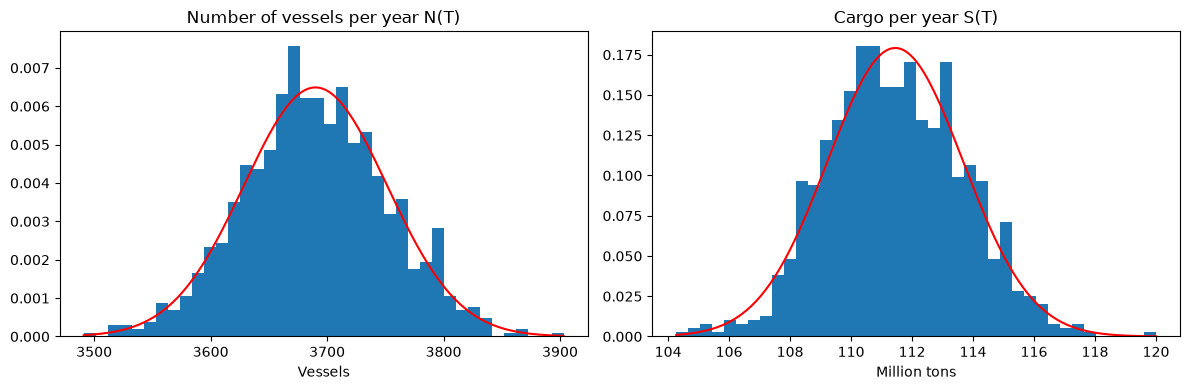

                 N          S
Arrival_Date                 
2022          3723  113127536
2023          3712  111588629
2024          3641  110031665


In [7]:
# Yearly totals with fitted normal (CLT)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(results['N(T)'], bins=40, density=True)
xs = np.linspace(results['N(T)'].min(), results['N(T)'].max(), 200)
ax[0].plot(xs, stats.norm(np.mean(results['N(T)']), np.std(results['N(T)'])).pdf(xs), 'r')
ax[0].set_title('Number of vessels per year N(T)')
ax[0].set_xlabel('Vessels')


ax[1].hist(results['S(T)'] / 1e6, bins=40, density=True)
xs = np.linspace(results['S(T)'].min(), results['S(T)'].max(), 200) / 1e6
ax[1].plot(xs, stats.norm(np.mean(results['S(T)']) / 1e6, np.std(results['S(T)']) / 1e6).pdf(xs), 'r')
ax[1].set_title('Cargo per year S(T)')
ax[1].set_xlabel('Million tons')
plt.tight_layout()
plt.show()


# observed yearly totals
obsYear = wd.groupby(wd['Arrival_Date'].dt.year).agg(N=('Vessel_ID', 'count'), S=('Cargo_tons', 'sum'))
print(obsYear)

In [8]:
# Daily throughput: simulated vs observed
dayN = simN.sum(axis=1).flatten()
dayS = simS.sum(axis=1).flatten()
obsDayN = wd.groupby('Day').size().reindex(allDays, fill_value=0).values
obsDayS = wd.groupby('Day')['Cargo_tons'].sum().reindex(allDays, fill_value=0).values


q = [0.5, 0.95, 0.99, 0.999]
summary = pd.DataFrame({
    'Simulated vessels/day': [np.mean(dayN), np.std(dayN)] + list(np.quantile(dayN, q)) + [np.max(dayN)],
    'Observed vessels/day':  [np.mean(obsDayN), np.std(obsDayN)] + list(np.quantile(obsDayN, q)) + [np.max(obsDayN)],
    'Simulated tons/day':    [np.mean(dayS), np.std(dayS)] + list(np.quantile(dayS, q)) + [np.max(dayS)],
    'Observed tons/day':     [np.mean(obsDayS), np.std(obsDayS)] + list(np.quantile(obsDayS, q)) + [np.max(obsDayS)]},
    index=['Mean', 'Std', 'Median', '95% quantile', '99% quantile', '99.9% quantile', 'Max'])
print(summary.round(1))

                Simulated vessels/day  Observed vessels/day  Simulated tons/day  Observed tons/day
Mean                             10.1                  10.1            305340.2           305426.9
Std                               3.2                   3.3            116536.2           118577.3
Median                           10.0                  10.0            295621.5           293841.5
95% quantile                     16.0                  16.0            512703.9           515667.0
99% quantile                     18.0                  19.0            616166.8           624000.8
99.9% quantile                   21.0                  21.0            739454.3           754824.5
Max                              27.0                  22.0           1128606.0           764676.0


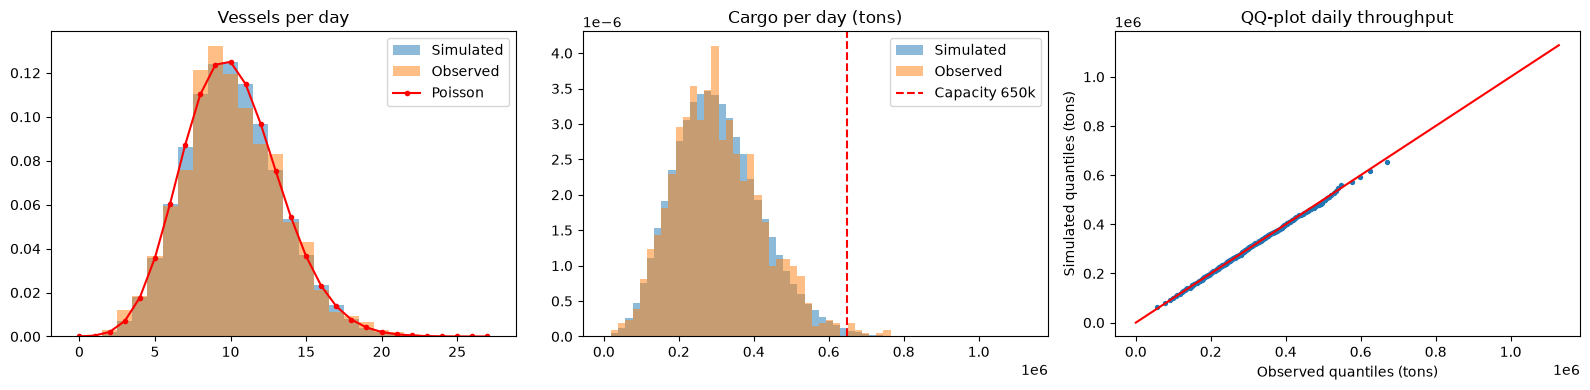

In [9]:
# Plots: vessels per day, cargo per day, QQ-plot
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
k = np.arange(0, dayN.max() + 1)
ax[0].hist(dayN, bins=np.arange(-0.5, dayN.max() + 1.5), density=True, alpha=0.5, label='Simulated')
ax[0].hist(obsDayN, bins=np.arange(-0.5, dayN.max() + 1.5), density=True, alpha=0.5, label='Observed')
ax[0].plot(k, stats.poisson(lamTot).pmf(k), 'ro-', ms=3, label='Poisson')
ax[0].set_title('Vessels per day')
ax[0].legend()


bins = np.linspace(0, max(dayS.max(), obsDayS.max()), 60)
ax[1].hist(dayS, bins=bins, density=True, alpha=0.5, label='Simulated')
ax[1].hist(obsDayS, bins=bins, density=True, alpha=0.5, label='Observed')
ax[1].axvline(capacity, color='r', ls='--', label='Capacity 650k')
ax[1].set_title('Cargo per day (tons)')
ax[1].legend()


probs = np.linspace(0.005, 0.995, 199)
ax[2].scatter(np.quantile(obsDayS, probs), np.quantile(dayS, probs), s=8)
lim = [0, max(dayS.max(), obsDayS.max())]
ax[2].plot(lim, lim, 'r')
ax[2].set_xlabel('Observed quantiles (tons)')
ax[2].set_ylabel('Simulated quantiles (tons)')
ax[2].set_title('QQ-plot daily throughput')
plt.tight_layout()
plt.show()

In [10]:
# Sources of uncertainty: variance share per type, and arrivals vs cargo size
# Var[S_i] = lambda_i E[X_i]^2 (arrivals) + lambda_i Var[X_i] (cargo size)
rows = []
for k, t in enumerate(types):
    sType = simS[:, k, :].flatten()
    rows.append([t, np.mean(sType), np.std(sType), np.var(sType) / np.var(dayS)])
print(pd.DataFrame(rows, columns=['Type', 'Mean tons/day', 'Std tons/day', 'Share of variance']).round(3).to_string(index=False))


varArrivals = sum(lam[t] * cargoDist[t].mean()**2 for t in types)
varCargo = sum(lam[t] * cargoDist[t].var() for t in types)
print('share of daily variance due to number of arrivals:', round(varArrivals / (varArrivals + varCargo), 3))
print('share of daily variance due to cargo per vessel:  ', round(varCargo / (varArrivals + varCargo), 3))

     Type  Mean tons/day  Std tons/day  Share of variance
Container      88300.207     39729.034              0.116
   Tanker     127691.981     89417.747              0.589
     Bulk      89347.999     63486.177              0.297
share of daily variance due to number of arrivals: 0.897
share of daily variance due to cargo per vessel:   0.103


busiest day of the year: mean = 715875  5% quantile = 631957  95% quantile = 824368
probability that the busiest day of a year exceeds capacity: 0.885


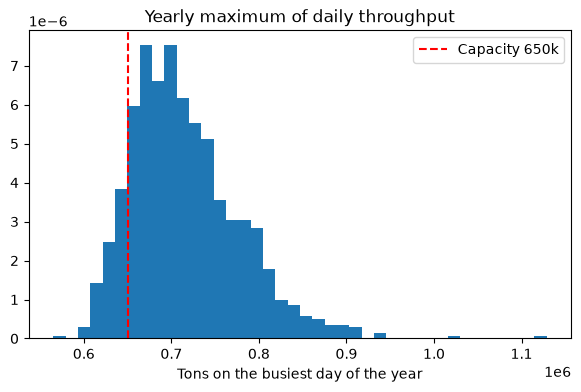

In [11]:
# Extremes: busiest day of each year
maxDayPerYear = simS.sum(axis=1).max(axis=1)
print('busiest day of the year: mean =', round(np.mean(maxDayPerYear)),
      ' 5% quantile =', round(np.quantile(maxDayPerYear, 0.05)),
      ' 95% quantile =', round(np.quantile(maxDayPerYear, 0.95)))
print('probability that the busiest day of a year exceeds capacity:', np.mean(maxDayPerYear > capacity))


plt.figure(figsize=(7, 4))
plt.hist(maxDayPerYear, bins=40, density=True)
plt.axvline(capacity, color='r', ls='--', label='Capacity 650k')
plt.xlabel('Tons on the busiest day of the year')
plt.title('Yearly maximum of daily throughput')
plt.legend()
plt.show()

P(daily throughput > 650k) = 0.00541  95% CI: ( 0.00517 , 0.00565 )
observed in the data: 0.00912 ( 10 days in 1096 )

congestion days per year: mean = 1.98  std = 1.38
P(no congestion day in a year)      = 0.115
P(5 or more congestion days a year) = 0.059
expected time between congestion days: 185 days


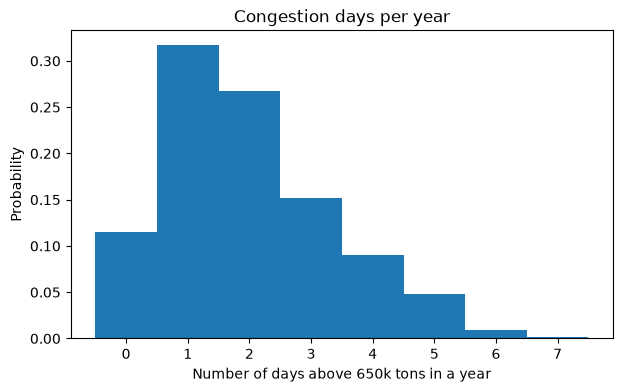

In [12]:
# Congestion: P(day > capacity) with 95% CI, and congestion days per year
congested = dayS > capacity
pCong = np.mean(congested)
halfWidth = 1.96 * np.std(congested) / np.sqrt(len(congested))
print('P(daily throughput > 650k) =', round(pCong, 5), ' 95% CI: (', round(pCong - halfWidth, 5), ',', round(pCong + halfWidth, 5), ')')
print('observed in the data:', round(np.mean(obsDayS > capacity), 5), '(', np.sum(obsDayS > capacity), 'days in', T_data, ')')
congDaysPerYear = (simS.sum(axis=1) > capacity).sum(axis=1)
print('\ncongestion days per year: mean =', round(np.mean(congDaysPerYear), 2), ' std =', round(np.std(congDaysPerYear), 2))
print('P(no congestion day in a year)      =', np.mean(congDaysPerYear == 0))
print('P(5 or more congestion days a year) =', np.mean(congDaysPerYear >= 5))
print('expected time between congestion days:', round(1 / pCong), 'days')


plt.figure(figsize=(7, 4))
plt.hist(congDaysPerYear, bins=np.arange(-0.5, congDaysPerYear.max() + 1.5), density=True)
plt.xlabel('Number of days above 650k tons in a year')
plt.ylabel('Probability')
plt.title('Congestion days per year')
plt.show()

In [13]:
# Longest run of consecutive congestion days per year
def longestRun(boolArray):
    longest = 0
    current = 0
    for b in boolArray:
        if b:
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest

runs = np.array([longestRun(simS[i].sum(axis=0) > capacity) for i in range(nrRuns)])
print('longest run of consecutive congestion days per year:')
print(pd.Series(runs).value_counts().sort_index())
# vessels per type on normal vs congestion days
dayNType = simN.transpose(1, 0, 2).reshape(len(types), -1)
compare = pd.DataFrame({'Normal day': dayNType[:, ~congested].mean(axis=1),
                        'Congestion day': dayNType[:, congested].mean(axis=1)}, index=types)
compare.loc['All'] = compare.sum()
print(compare.round(2))

longest run of consecutive congestion days per year:
0    115
1    872
2     13
Name: count, dtype: int64
           Normal day  Congestion day
Container        5.58            7.36
Tanker           2.21            6.07
Bulk             2.28            4.58
All             10.07           18.02
